=== Data Audit ===
Shape: (143, 10) | Missing values: 0 | Duplicates: 0
Date range: 2010-02-05 to 2012-10-26

Train rows: 113 (2010-02-12 to 2012-04-06)
Test rows:  29 (2012-04-13 to 2012-10-26)

Training Median Weekly_Sales Threshold: $1,525,147.09

=== Naive Last-Week Baseline ===
Overall          -> MAE: $96,637.02 | RMSE: $123,562.76 | MAPE: 6.06%
Holiday (n=1)    -> MAE: $79,683.93 | RMSE: $79,683.93 | MAPE: 4.80%
Non-Holiday (n=28) -> MAE: $97,242.49 | RMSE: $124,844.96 | MAPE: 6.10%

=== Linear Regression ===
Overall          -> MAE: $148,638.87 | RMSE: $178,987.34 | MAPE: 9.69%
Holiday (n=1)    -> MAE: $123,543.05 | RMSE: $123,543.05 | MAPE: 7.43%
Non-Holiday (n=28) -> MAE: $149,535.15 | RMSE: $180,653.05 | MAPE: 9.78%

=== Ranked Drivers of Weekly_Sales (Linear Regression) ===
 Rank      Feature      Std_Coef  Abs_Std_Coef       Raw_Coef
    1        Month  64411.613587  64411.613587   18563.043569
    2  Temperature -51210.846793  51210.846793   -3453.586398
    3 Unemploymen

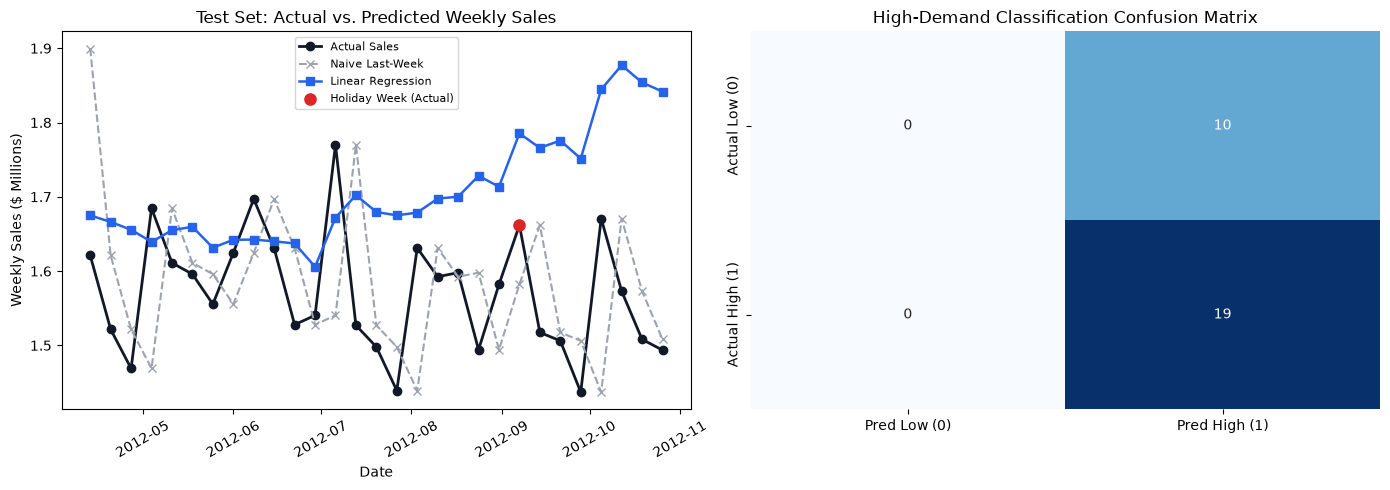

Saved models and scalers in: D:\PROJECTS\models


In [2]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression
from pathlib import Path
import joblib
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    mean_absolute_error,
    mean_absolute_percentage_error,
    precision_score,
    recall_score,
    root_mean_squared_error,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


df = pd.read_csv("sorted_data.xls")
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

print("=== Data Audit ===")
print(
    f"Shape: {df.shape} | Missing values: {df.isna().sum().sum()} |"
    f" Duplicates: {df.duplicated().sum()}"
)
print(f"Date range: {df['Date'].min().date()} to {df['Date'].max().date()}")

# Create strictly past 1-week lag and drop the initial NaN row
df["sales_lag_1"] = df["Weekly_Sales"].shift(1)
clean_df = df.dropna(subset=["sales_lag_1"]).reset_index(drop=True)

features = [
    "Holiday_Flag",
    "Temperature",
    "Fuel_Price",
    "CPI",
    "Unemployment",
    "Month",
    "sales_lag_1",
]
target = "Weekly_Sales"

# Chronological 80/20 split using train_test_split with shuffle=False
train_df, test_df = train_test_split(clean_df, test_size=0.2, shuffle=False)
train_df = train_df.copy()
test_df = test_df.copy()

X_train, y_train = train_df[features], train_df[target]
X_test, y_test = test_df[features], test_df[target]

print(
    f"\nTrain rows: {len(train_df)} ({train_df['Date'].min().date()} to"
    f" {train_df['Date'].max().date()})"
)
print(
    f"Test rows:  {len(test_df)} ({test_df['Date'].min().date()} to"
    f" {test_df['Date'].max().date()})"
)

# 1. Naive last-week baseline
naive_preds = X_test["sales_lag_1"].values

# 2. Linear Regression to forecast Weekly_Sales (fit scaler on X_train only)
reg_scaler = StandardScaler()
X_train_reg_scaled = reg_scaler.fit_transform(X_train)
X_test_reg_scaled = reg_scaler.transform(X_test)

lin_model = LinearRegression()
lin_model.fit(X_train_reg_scaled, y_train)
lin_preds = lin_model.predict(X_test_reg_scaled)

# 3. Logistic Regression to flag high-demand weeks (> training median)
train_median = y_train.median()
y_train_high = (y_train > train_median).astype(int)
y_test_high = (y_test > train_median).astype(int)

clf_scaler = StandardScaler()
X_train_clf_scaled = clf_scaler.fit_transform(X_train)
X_test_clf_scaled = clf_scaler.transform(X_test)

clf_model = LogisticRegression(random_state=42)
clf_model.fit(X_train_clf_scaled, y_train_high)
high_preds = clf_model.predict(X_test_clf_scaled)

print(f"\nTraining Median Weekly_Sales Threshold: ${train_median:,.2f}")


# %% [Cell 4] Evaluate Forecasts (MAE, RMSE, MAPE + Separate Holiday-Week Error)
def evaluate_forecasts(name, y_true, y_pred, holiday_flag):
  mae = mean_absolute_error(y_true, y_pred)
  rmse = root_mean_squared_error(y_true, y_pred)
  mape = mean_absolute_percentage_error(y_true, y_pred) * 100

  print(f"\n=== {name} ===")
  print(
      f"Overall          -> MAE: ${mae:,.2f} | RMSE: ${rmse:,.2f} | MAPE:"
      f" {mape:.2f}%"
  )

  hol_mask = holiday_flag == 1
  non_hol_mask = holiday_flag == 0

  if hol_mask.sum() > 0:
    h_mae = mean_absolute_error(y_true[hol_mask], y_pred[hol_mask])
    h_rmse = root_mean_squared_error(y_true[hol_mask], y_pred[hol_mask])
    h_mape = (
        mean_absolute_percentage_error(y_true[hol_mask], y_pred[hol_mask]) * 100
    )
    print(
        f"Holiday (n={hol_mask.sum()})    -> MAE: ${h_mae:,.2f} |"
        f" RMSE: ${h_rmse:,.2f} | MAPE: {h_mape:.2f}%"
    )
  else:
    print("Holiday (n=0)    -> No holiday weeks in test set.")

  if non_hol_mask.sum() > 0:
    nh_mae = mean_absolute_error(y_true[non_hol_mask], y_pred[non_hol_mask])
    nh_rmse = root_mean_squared_error(y_true[non_hol_mask], y_pred[non_hol_mask])
    nh_mape = (
        mean_absolute_percentage_error(y_true[non_hol_mask], y_pred[non_hol_mask])
        * 100
    )
    print(
        f"Non-Holiday (n={non_hol_mask.sum()}) -> MAE: ${nh_mae:,.2f} |"
        f" RMSE: ${nh_rmse:,.2f} | MAPE: {nh_mape:.2f}%"
    )


evaluate_forecasts(
    "Naive Last-Week Baseline",
    y_test.values,
    naive_preds,
    test_df["Holiday_Flag"].values,
)
evaluate_forecasts(
    "Linear Regression",
    y_test.values,
    lin_preds,
    test_df["Holiday_Flag"].values,
)

# %% [Cell 5] Rank Drivers of Sales from Standardized Linear Regression Coefficients
drivers_df = (
    pd.DataFrame({
        "Feature": features,
        "Std_Coef": lin_model.coef_,
        "Abs_Std_Coef": np.abs(lin_model.coef_),
        "Raw_Coef": lin_model.coef_ / reg_scaler.scale_,
    })
    .sort_values("Abs_Std_Coef", ascending=False)
    .reset_index(drop=True)
)
drivers_df.insert(0, "Rank", drivers_df.index + 1)

print("\n=== Ranked Drivers of Weekly_Sales (Linear Regression) ===")
print(drivers_df.to_string(index=False))

# %% [Cell 6] Evaluate High-Demand Classification (Accuracy, Precision, Recall, Confusion Matrix)
acc = accuracy_score(y_test_high, high_preds)
prec = precision_score(y_test_high, high_preds, zero_division=0)
rec = recall_score(y_test_high, high_preds, zero_division=0)
cm = confusion_matrix(y_test_high, high_preds)

print("\n=== High-Demand Week Classification (Logistic Regression) ===")
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print("Confusion Matrix [rows=Actual 0/1, cols=Pred 0/1]:")
print(cm)

# %% [Cell 7] Visualize Actual vs. Predicted Sales & Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    test_df["Date"],
    y_test.values / 1e6,
    marker="o",
    linewidth=2,
    color="#111827",
    label="Actual Sales",
)
axes[0].plot(
    test_df["Date"],
    naive_preds / 1e6,
    marker="x",
    linestyle="--",
    color="#9CA3AF",
    label="Naive Last-Week",
)
axes[0].plot(
    test_df["Date"],
    lin_preds / 1e6,
    marker="s",
    linewidth=1.8,
    color="#2563EB",
    label="Linear Regression",
)

hol_test = test_df[test_df["Holiday_Flag"] == 1]
if not hol_test.empty:
  axes[0].scatter(
      hol_test["Date"],
      hol_test["Weekly_Sales"] / 1e6,
      color="#DC2626",
      s=65,
      zorder=6,
      label="Holiday Week (Actual)",
  )

axes[0].set_title("Test Set: Actual vs. Predicted Weekly Sales")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Weekly Sales ($ Millions)")
axes[0].legend(fontsize=8)
axes[0].tick_params(axis="x", rotation=30)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Pred Low (0)", "Pred High (1)"],
    yticklabels=["Actual Low (0)", "Actual High (1)"],
    ax=axes[1],
)
axes[1].set_title("High-Demand Classification Confusion Matrix")

plt.tight_layout()
plt.savefig("sales_modeling_results.png", dpi=150)
plt.show()



models_dir = Path("models")
models_dir.mkdir(exist_ok=True)

joblib.dump(reg_scaler, models_dir / "reg_scaler.joblib")
joblib.dump(lin_model, models_dir / "linear_regression_model.joblib")

joblib.dump(clf_scaler, models_dir / "clf_scaler.joblib")
joblib.dump(clf_model, models_dir / "logistic_regression_model.joblib")

joblib.dump(train_median, models_dir / "train_median.joblib")

print("Saved models and scalers in:", models_dir.resolve())